# 03 · Fast models: Ridge, PCA + Ridge, Decision Tree, LightGBM, XGBoost, CatBoost
Same protocol for all (see `src/models.py`): tune on a 300k-row month-stratified subset of **train**, early-stop and
score on **validation**, refit the best configuration on all train rows, save validation predictions.
Results are saved after every model, so you can stop and restart: finished models are skipped.
Rough time on a laptop: Ridge/PCA/Tree seconds-minutes, LightGBM minutes, XGBoost and CatBoost 10-40 minutes each.

In [3]:
import sys, os, json, time, warnings
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore")

ROOT = Path.cwd()
while not (ROOT / "data").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT)); os.chdir(ROOT)
from src import evaluate as ev, metrics as M, models as mo
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.3, "axes.spines.top": False,
                     "axes.spines.right": False, "font.size": 10, "axes.titleweight": "bold"})
def savefig(fig, name):
    fig.tight_layout(); fig.savefig(ev.FIGS / f"{name}.png", dpi=150); plt.show()
print("results folder:", ev.RESULTS, "| smoke mode:", mo.SMOKE, "| threads:", mo.N_JOBS)

results folder: C:\dev\traffic-prediction\results | smoke mode: False | threads: 11


## Run the models (both horizons)

In [4]:
FAST = ["ridge", "pca_ridge", "dt", "lgbm", "xgb", "cat"]       # ridge first: PCA reuses its best penalty
summary = []
for name in FAST:
    for h in ev.HORIZONS:
        r = mo.tune_model(name, h)
        summary.append({"model": mo.LABEL[name], "horizon_min": h, "val MAE": r["val"]["MAE"], "RMSE": r["val"]["RMSE"],
                        "WAPE_%": r["val"]["WAPE"] * 100, "best_iter": r["best_iter"], "fit_s": r["fit_s_train"], "params": r["params"]})
display(pd.DataFrame(summary).round(2))

[ridge h=15] already done -> ridge_h15.json
[ridge h=60] already done -> ridge_h60.json
[pca_ridge h=15] already done -> pca_ridge_h15.json
[pca_ridge h=60] already done -> pca_ridge_h60.json
[dt h=15] already done -> dt_h15.json
[dt h=60] already done -> dt_h60.json
[lgbm h=15] already done -> lgbm_h15.json
[lgbm h=60] already done -> lgbm_h60.json
[xgb h=15] already done -> xgb_h15.json
[xgb h=60] cfg 1/6 {'subsample': 1.0, 'reg_lambda': 1, 'min_child_weight': 50, 'max_depth': 4, 'learning_rate': 0.1, 'colsample_bytree': 1.0} -> val MAE 64.82  (164s)
[xgb h=60] cfg 2/6 {'subsample': 1.0, 'reg_lambda': 10, 'min_child_weight': 10, 'max_depth': 6, 'learning_rate': 0.05, 'colsample_bytree': 0.7} -> val MAE 63.68  (193s)
[xgb h=60] cfg 3/6 {'subsample': 0.7, 'reg_lambda': 10, 'min_child_weight': 50, 'max_depth': 4, 'learning_rate': 0.05, 'colsample_bytree': 1.0} -> val MAE 66.10  (116s)
[xgb h=60] cfg 4/6 {'subsample': 1.0, 'reg_lambda': 1, 'min_child_weight': 1, 'max_depth': 8, 'learning

,model,horizon_min,val MAE,RMSE,WAPE_%,best_iter,fit_s,params
0,Ridge,15,57.36,87.32,6.45,NaN,2.57,{'alpha': 0.01}
1,Ridge,60,80.49,122.60,9.05,NaN,2.51,{'alpha': 0.01}
2,PCA + Ridge,15,57.36,87.32,6.45,NaN,0.58,"{'k': 31, 'alpha': 0.01}"
3,PCA + Ridge,60,80.49,122.60,9.05,NaN,0.55,"{'k': 31, 'alpha': 0.01}"
4,Decision Tree,15,52.31,83.41,5.88,NaN,23.30,"{'max_depth': 14, 'min_samples_leaf': 100}"
5,Decision Tree,60,70.06,111.48,7.88,NaN,24.21,"{'max_depth': 14, 'min_samples_leaf': 50}"
6,LightGBM,15,47.97,78.19,5.39,1414.0,87.15,"{'reg_lambda': 10, 'num_leaves': 127, 'min_chi..."
7,LightGBM,60,62.00,100.48,6.97,1695.0,147.07,"{'reg_lambda': 10, 'num_leaves': 127, 'min_chi..."
8,XGBoost,15,48.06,78.29,5.40,1943.0,243.86,"{'subsample': 1.0, 'reg_lambda': 1, 'min_child..."
9,XGBoost,60,62.14,100.76,6.99,2088.0,204.21,"{'subsample': 1.0, 'reg_lambda': 1, 'min_child..."


## PCA: how many components are needed?
If PCA with k components matches plain Ridge, the 31 features are redundant (as the correlation heatmap suggested).

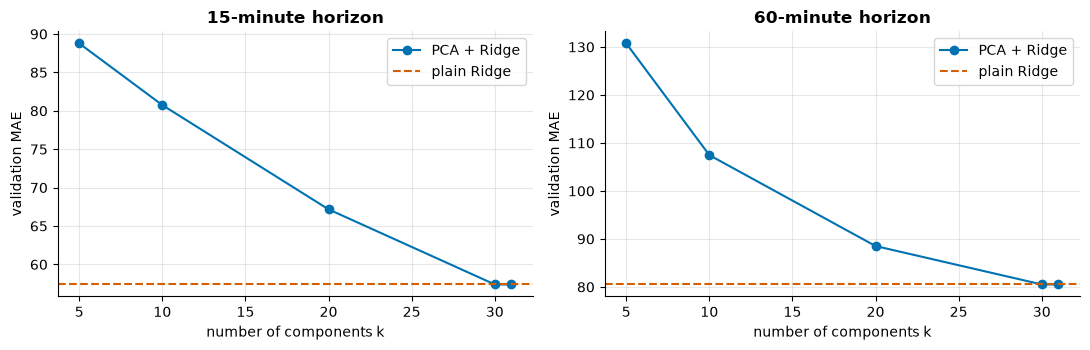

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6), sharey=False)
for ax, h in zip(axes, ev.HORIZONS):
    lg = pd.read_csv(ev.LOGS / f"tuning_pca_ridge_h{h}.csv").sort_values("k")
    ax.plot(lg["k"], lg["val_MAE"], "o-", color="#0072B2", label="PCA + Ridge")
    rg = pd.read_csv(ev.LOGS / f"tuning_ridge_h{h}.csv")["val_MAE"].min()
    ax.axhline(rg, color="#D55E00", ls="--", label="plain Ridge")
    ax.set_xlabel("number of components k"); ax.set_ylabel("validation MAE"); ax.set_title(f"{h}-minute horizon"); ax.legend()
savefig(fig, "model_pca_curve")

## Decision tree: depth vs error (over- vs under-fitting)

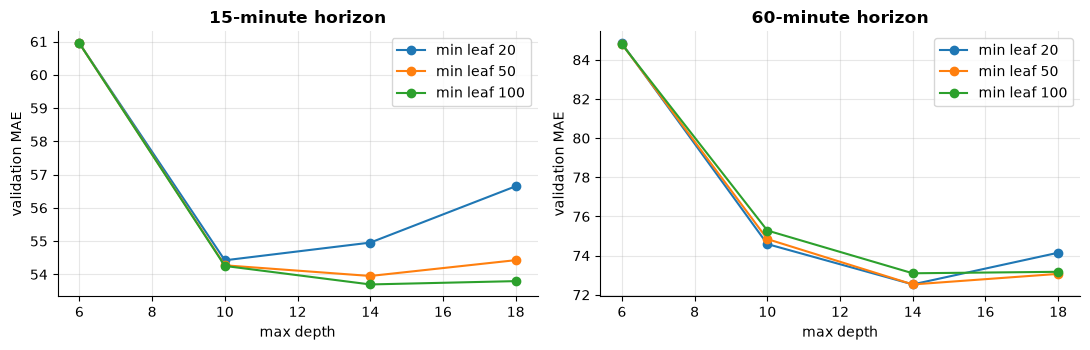

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
for ax, h in zip(axes, ev.HORIZONS):
    lg = pd.read_csv(ev.LOGS / f"tuning_dt_h{h}.csv")
    for leaf, g in lg.groupby("min_samples_leaf"):
        g = g.sort_values("max_depth"); ax.plot(g["max_depth"], g["val_MAE"], "o-", label=f"min leaf {leaf}")
    ax.set_xlabel("max depth"); ax.set_ylabel("validation MAE"); ax.set_title(f"{h}-minute horizon"); ax.legend()
savefig(fig, "model_tree_depth")

## Boosting: tuning trials and how many trees were kept

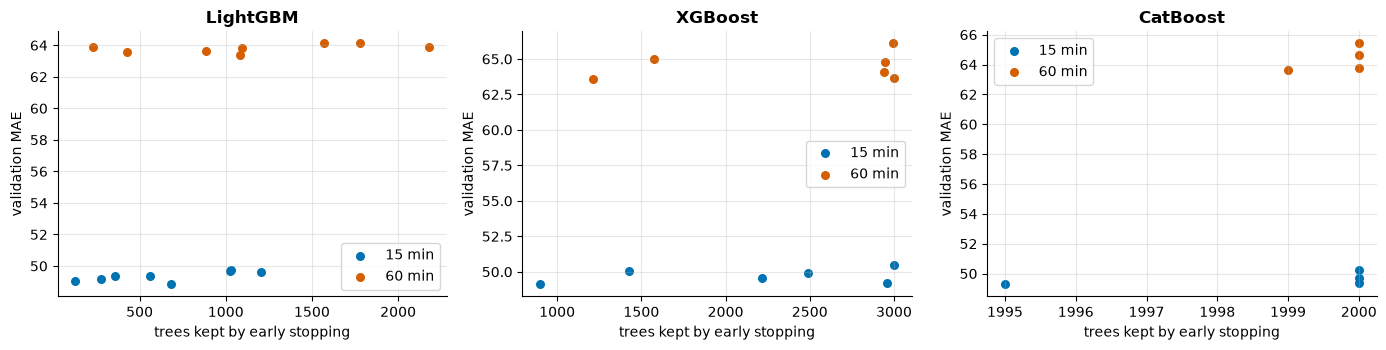

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.6))
for ax, name in zip(axes, ["lgbm", "xgb", "cat"]):
    for h, col in zip(ev.HORIZONS, ["#0072B2", "#D55E00"]):
        lg = pd.read_csv(ev.LOGS / f"tuning_{name}_h{h}.csv")
        ax.scatter(lg["best_iter"], lg["val_MAE"], color=col, label=f"{h} min", s=30)
    ax.set_title(mo.LABEL[name]); ax.set_xlabel("trees kept by early stopping"); ax.set_ylabel("validation MAE"); ax.legend()
savefig(fig, "model_boosting_trials")

## Slow models: status
Random Forest, AdaBoost and Gradient Boosting run as scripts (they can take hours). In a **terminal** (venv active):
```
python scripts/run_model.py tune --models rf --h 15 60
python scripts/run_model.py tune --models ada gb --h 15 60
```
This cell shows what is finished.

In [8]:
for name in ["rf", "ada", "gb"]:
    for h in ev.HORIZONS:
        r = ev.read_best(name, h)
        print(f"{mo.LABEL[name]:18s} h={h:2d}  " + (f"done  val MAE {r['val']['MAE']:.2f}  params {r['params']}" if r else "not run yet"))

Random Forest      h=15  not run yet
Random Forest      h=60  not run yet
AdaBoost           h=15  not run yet
AdaBoost           h=60  not run yet
Gradient Boosting  h=15  not run yet
Gradient Boosting  h=60  not run yet
